# IMAES - Experiment 8
## Multi-Agent Task Allocation and Coordination

**Aim:** To implement a simple multi-agent task allocation system using Partial Global Planning (PGP) and Contract Net Protocol (CNP).

### Exercises
1. Create 1 Manager Agent and 3 Delivery Agents with at least 6 delivery tasks.
2. Create local plans, detect a shared location/resource conflict, and resolve it using PGP.
3. Implement the CNP sequence: Task Announcement -> Bidding -> Bid Comparison -> Agent Selection -> Task Assignment.
4. Automatically allocate all tasks and calculate total cost/time.
5. Modify selected costs, rerun allocation, compare results, and visualize Agent vs Total Assigned Cost/Time.

## Theory

**Multi-agent task allocation** distributes tasks among autonomous agents according to their capabilities, costs, availability, or execution times.

**Partial Global Planning (PGP)** allows agents to coordinate using partial views of the global plan. Local plans are exchanged or checked for conflicts, and agents modify their plans to remove resource or scheduling conflicts.

**Contract Net Protocol (CNP)** is a manager-worker negotiation protocol. A manager announces a task, agents submit bids, the manager compares bids, selects an agent, and assigns the task to the winning agent.

In this experiment, the Manager Agent performs coordination and the Delivery Agents provide bids for delivery tasks.

## 1. Agent Setup

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from dataclasses import dataclass

@dataclass
class DeliveryAgent:
    name: str

agents = [
    DeliveryAgent("Agent_A"),
    DeliveryAgent("Agent_B"),
    DeliveryAgent("Agent_C")
]

tasks = ["T1", "T2", "T3", "T4", "T5", "T6"]

# Cost/time for every agent on every task.
cost_matrix = pd.DataFrame(
    {
        "Agent_A": [10, 14, 8, 16, 12, 18],
        "Agent_B": [12, 9, 13, 11, 17, 15],
        "Agent_C": [15, 11, 10, 13, 9, 12],
    },
    index=tasks
)

print("Agents:")
for agent in agents:
    print("-", agent.name)

print("\nTask cost/time matrix:")
display(cost_matrix)

/home/oai/.config/matplotlib is not a writable directory


Matplotlib created a temporary cache directory at /tmp/matplotlib-_9fhho7u because there was an issue with the default path (/home/oai/.config/matplotlib); it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.


Agents:
- Agent_A
- Agent_B
- Agent_C

Task cost/time matrix:


,Agent_A,Agent_B,Agent_C
T1,10,12,15
T2,14,9,11
T3,8,13,10
T4,16,11,13
T5,12,17,9
T6,18,15,12


### Observation
The system contains one logical Manager Agent and three Delivery Agents. Six tasks are available, and every agent has a different cost/time for each task, which makes bidding meaningful.

## 2. PGP Coordination

In [ ]:
# Local plans deliberately contain a conflict:
# Agent_A and Agent_B both use Depot_X at time slot 2.
local_plans = {
    "Agent_A": [
        {"task": "T1", "location": "Depot_X", "time": 1},
        {"task": "T3", "location": "Depot_X", "time": 2},
    ],
    "Agent_B": [
        {"task": "T2", "location": "Depot_Y", "time": 1},
        {"task": "T4", "location": "Depot_X", "time": 2},
    ],
    "Agent_C": [
        {"task": "T5", "location": "Depot_Z", "time": 1},
        {"task": "T6", "location": "Depot_Z", "time": 2},
    ],
}

def detect_conflicts(plans):
    occupied = {}
    conflicts = []
    for agent, plan in plans.items():
        for item in plan:
            key = (item["location"], item["time"])
            if key in occupied and occupied[key] != agent:
                conflicts.append({
                    "location": item["location"],
                    "time": item["time"],
                    "agents": [occupied[key], agent]
                })
            else:
                occupied[key] = agent
    return conflicts

conflicts_before = detect_conflicts(local_plans)
print("Conflicts before PGP resolution:")
for c in conflicts_before:
    print(c)

Conflicts before PGP resolution:
{'location': 'Depot_X', 'time': 2, 'agents': ['Agent_A', 'Agent_B']}


In [ ]:
# PGP resolution:
# Move Agent_B's conflicting task T4 from time 2 to time 3.
resolved_plans = {k: [dict(x) for x in v] for k, v in local_plans.items()}
for item in resolved_plans["Agent_B"]:
    if item["task"] == "T4":
        item["time"] = 3

conflicts_after = detect_conflicts(resolved_plans)

print("Updated Agent_B plan:")
for item in resolved_plans["Agent_B"]:
    print(item)

print("\nConflicts after PGP resolution:", conflicts_after)
print("PGP conflict resolved:", len(conflicts_after) == 0)

Updated Agent_B plan:
{'task': 'T2', 'location': 'Depot_Y', 'time': 1}
{'task': 'T4', 'location': 'Depot_X', 'time': 3}

Conflicts after PGP resolution: []
PGP conflict resolved: True


### PGP Observation
Initially, Agent_A and Agent_B both use `Depot_X` at time 2. The conflict is detected from the combined partial plans. Agent_B's conflicting task is moved to time 3, producing a conflict-free coordinated plan.

## 3. CNP Task Allocation

In [ ]:
# CNP implementation
def announce_task(task):
    print(f"Task Announcement: Manager announces {task}")

def collect_bids(task, matrix):
    bids = matrix.loc[task].to_dict()
    print(f"Bids for {task}: {bids}")
    return bids

def compare_bids(bids):
    return min(bids.items(), key=lambda x: x[1])

def allocate_task_cnp(task, matrix, verbose=True):
    announce_task(task)
    bids = collect_bids(task, matrix)
    selected_agent, winning_cost = compare_bids(bids)
    if verbose:
        print(f"Agent Selection: {selected_agent} with cost/time {winning_cost}")
        print(f"Task Assignment: {task} -> {selected_agent}")
    return selected_agent, winning_cost

print("Demonstration for T1:")
allocate_task_cnp("T1", cost_matrix)

Demonstration for T1:
Task Announcement: Manager announces T1
Bids for T1: {'Agent_A': 10, 'Agent_B': 12, 'Agent_C': 15}
Agent Selection: Agent_A with cost/time 10
Task Assignment: T1 -> Agent_A


('Agent_A', 10)

## 4. Multiple Task Allocation

In [ ]:
def allocate_all_tasks(matrix):
    records = []
    for task in matrix.index:
        bids = matrix.loc[task].to_dict()
        selected_agent, cost = min(bids.items(), key=lambda x: x[1])
        records.append({
            "Task": task,
            "Selected Agent": selected_agent,
            "Cost/Time": cost
        })
    return pd.DataFrame(records)

allocation_1 = allocate_all_tasks(cost_matrix)

print("Final CNP Allocation:")
display(allocation_1)

total_cost_1 = allocation_1["Cost/Time"].sum()
print(f"Total Cost/Time = {total_cost_1}")

Final CNP Allocation:


,Task,Selected Agent,Cost/Time
0,T1,Agent_A,10
1,T2,Agent_B,9
2,T3,Agent_A,8
3,T4,Agent_B,11
4,T5,Agent_C,9
5,T6,Agent_C,12


Total Cost/Time = 59


In [ ]:
agent_totals_1 = allocation_1.groupby("Selected Agent")["Cost/Time"].sum().reindex(
    [a.name for a in agents], fill_value=0
)

print("Agent-wise total assigned Cost/Time:")
display(agent_totals_1.to_frame("Total Assigned Cost/Time"))

Agent-wise total assigned Cost/Time:


,Total Assigned Cost/Time
Selected Agent,
Agent_A,18
Agent_B,20
Agent_C,21


### Observation
CNP assigns each task to the agent offering the lowest bid. The final allocation table identifies the selected agent and the corresponding cost/time, while the sum gives the total system cost/time.

## 5. Modification and Reallocation

In [ ]:
# Modify selected input costs to change the negotiation outcome.
modified_matrix = cost_matrix.copy()
modified_matrix.loc["T1", "Agent_A"] = 22
modified_matrix.loc["T5", "Agent_C"] = 19
modified_matrix.loc["T6", "Agent_B"] = 8

print("Modified cost/time matrix:")
display(modified_matrix)

allocation_2 = allocate_all_tasks(modified_matrix)
print("Allocation after modification:")
display(allocation_2)

total_cost_2 = allocation_2["Cost/Time"].sum()
print(f"Original total Cost/Time = {total_cost_1}")
print(f"Modified total Cost/Time = {total_cost_2}")

Modified cost/time matrix:


,Agent_A,Agent_B,Agent_C
T1,22,12,15
T2,14,9,11
T3,8,13,10
T4,16,11,13
T5,12,17,19
T6,18,8,12


Allocation after modification:


,Task,Selected Agent,Cost/Time
0,T1,Agent_B,12
1,T2,Agent_B,9
2,T3,Agent_A,8
3,T4,Agent_B,11
4,T5,Agent_A,12
5,T6,Agent_B,8


Original total Cost/Time = 59
Modified total Cost/Time = 60


In [ ]:
comparison = allocation_1.merge(
    allocation_2,
    on="Task",
    suffixes=(" - Original", " - Modified")
)

print("Allocation comparison:")
display(comparison)

agent_totals_2 = allocation_2.groupby("Selected Agent")["Cost/Time"].sum().reindex(
    [a.name for a in agents], fill_value=0
)

summary = pd.DataFrame({
    "Original Total": agent_totals_1,
    "Modified Total": agent_totals_2
})
display(summary)

Allocation comparison:


,Task,Selected Agent - Original,Cost/Time - Original,Selected Agent - Modified,Cost/Time - Modified
0,T1,Agent_A,10,Agent_B,12
1,T2,Agent_B,9,Agent_B,9
2,T3,Agent_A,8,Agent_A,8
3,T4,Agent_B,11,Agent_B,11
4,T5,Agent_C,9,Agent_A,12
5,T6,Agent_C,12,Agent_B,8


,Original Total,Modified Total
Selected Agent,,
Agent_A,18,20
Agent_B,20,40
Agent_C,21,0


## 6. Visualization

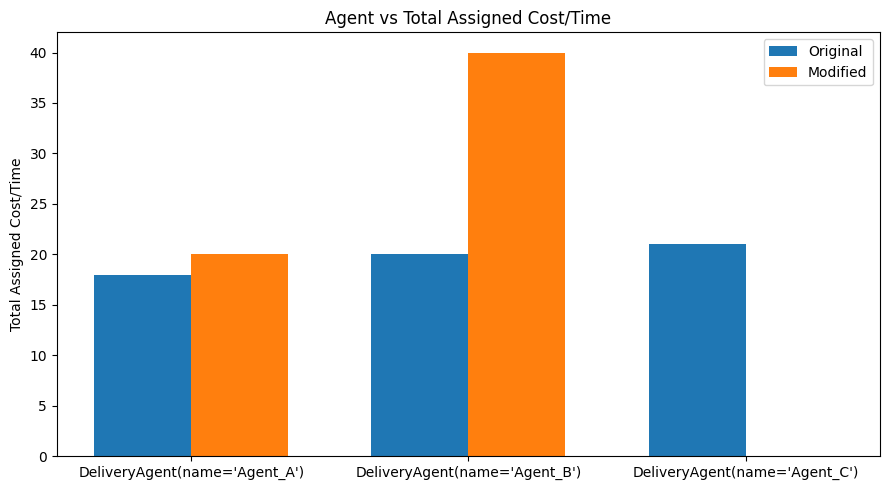

In [ ]:
x = np.arange(len(agents))
width = 0.35

plt.figure(figsize=(9, 5))
plt.bar(x - width/2, agent_totals_1.values, width, label="Original")
plt.bar(x + width/2, agent_totals_2.values, width, label="Modified")
plt.xticks(x, agents)
plt.ylabel("Total Assigned Cost/Time")
plt.title("Agent vs Total Assigned Cost/Time")
plt.legend()
plt.tight_layout()
plt.show()

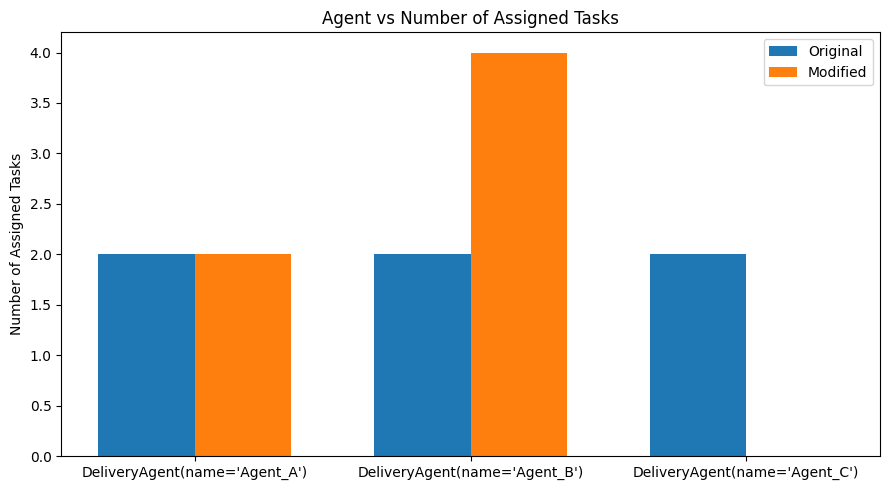

In [ ]:
# Task allocation visualization
allocation_counts_1 = allocation_1["Selected Agent"].value_counts().reindex(
    [a.name for a in agents], fill_value=0
)
allocation_counts_2 = allocation_2["Selected Agent"].value_counts().reindex(
    [a.name for a in agents], fill_value=0
)

x = np.arange(len(agents))
plt.figure(figsize=(9, 5))
plt.bar(x - width/2, allocation_counts_1.values, width, label="Original")
plt.bar(x + width/2, allocation_counts_2.values, width, label="Modified")
plt.xticks(x, agents)
plt.ylabel("Number of Assigned Tasks")
plt.title("Agent vs Number of Assigned Tasks")
plt.legend()
plt.tight_layout()
plt.show()

## Observations

1. **PGP:** The initial local plans contain a shared resource conflict at `Depot_X` and time 2. The conflict is detected and resolved by modifying Agent_B's schedule.
2. **CNP:** Each task is announced by the manager, agents submit bids, the bids are compared, and the lowest-cost agent is selected.
3. **Multiple allocation:** All six tasks are automatically assigned according to the minimum bid.
4. **Modification:** Changing agent/task costs can change the winning agent and therefore the final allocation and total cost/time.
5. **Visualization:** The agent-wise cost/time chart makes the redistribution caused by modified bids visible.

## Conclusion

The experiment demonstrates two important multi-agent coordination mechanisms. Partial Global Planning resolves conflicts between independently constructed local plans by identifying shared resources and modifying a plan. Contract Net Protocol provides a structured negotiation mechanism in which a manager announces tasks, agents bid, and the manager assigns each task to the selected bidder. The experiment also shows that changes in local agent costs can alter task ownership and system-level cost/time.